# 06 · Evaluasi

Membedah model akhir: rumah seperti apa yang paling meleset, dan fitur apa yang paling menentukan harga.

In [1]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

pd.options.display.float_format = "{:,.1f}".format

model = joblib.load("../models/model_xgb.joblib")
X_test = pd.read_csv("../data/processed/X_test.csv")
y_test_log = pd.read_csv("../data/processed/y_test_log.csv").squeeze("columns")

ev = pd.DataFrame({
    "asli_juta":    np.expm1(y_test_log) / 1e6,
    "tebakan_juta": np.expm1(model.predict(X_test)) / 1e6,
})
ev["meleset_pct"] = (ev["tebakan_juta"] - ev["asli_juta"]).abs() / ev["asli_juta"] * 100
ev["arah"] = np.where(ev["tebakan_juta"] > ev["asli_juta"], "kemahalan", "kemurahan")

kolom_kota = [c for c in X_test.columns if c.startswith("city_")]
ev["kota"] = X_test[kolom_kota].idxmax(axis=1).str.replace("city_", "")
ev["luas_bangunan"] = X_test["building_size_m2"]

print("MAPE:", round(ev["meleset_pct"].mean(), 1), "| median:", round(ev["meleset_pct"].median(), 1))
ev.head()

MAPE: 20.3 | median: 13.3


,asli_juta,tebakan_juta,meleset_pct,arah,kota,luas_bangunan
0,"2,700.0","3,186.3",18.0,kemahalan,Bekasi,136.0
1,"5,360.0","3,913.2",27.0,kemurahan,Bekasi,370.0
2,"1,980.0","2,204.4",11.3,kemahalan,Bekasi,98.0
3,"2,000.0","1,804.5",9.8,kemurahan,Bekasi,155.0
4,"1,900.0","1,490.0",21.6,kemurahan,Bekasi,120.0


In [2]:
ev["kelas_harga"] = pd.qcut(ev["asli_juta"], 4, labels=["murah", "sedang", "mahal", "sangat mahal"])

ev.groupby("kelas_harga", observed=True).agg(
    jumlah=("asli_juta", "size"),
    harga_maks_juta=("asli_juta", "max"),
    mape=("meleset_pct", "mean"),
    median_meleset=("meleset_pct", "median"),
)

,jumlah,harga_maks_juta,mape,median_meleset
kelas_harga,,,,
murah,160,875.0,21.3,12.9
sedang,160,"1,580.0",17.4,14.7
mahal,161,"4,200.0",19.0,12.8
sangat mahal,158,"110,000.0",23.5,13.5


MAPE berbeda antarkelas harga, tapi mediannya mirip (±13–15%). Jadi untuk rumah pada umumnya model sama baiknya di semua kelas. Perbedaan MAPE datang dari segelintir rumah yang melesetnya parah.

,jumlah,mape,median_meleset
kota,,,
Depok,82,14.1,11.6
Jakarta_Barat,40,14.9,11.4
Tangerang,164,19.0,12.8
Jakarta_Timur,9,20.6,18.8
Jakarta_Utara,23,20.7,16.4
Bogor,162,21.3,10.9
Bekasi,117,23.7,18.0
Jakarta_Selatan,34,28.1,23.2
Jakarta_Pusat,8,33.8,27.3


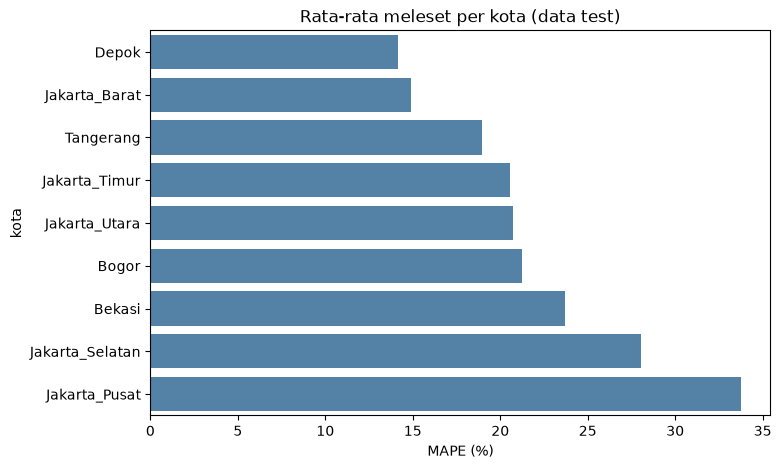

In [3]:
per_kota = (ev.groupby("kota")
              .agg(jumlah=("asli_juta", "size"),
                   mape=("meleset_pct", "mean"),
                   median_meleset=("meleset_pct", "median"))
              .sort_values("mape"))
display(per_kota)

plt.figure(figsize=(8, 5))
sns.barplot(x=per_kota["mape"], y=per_kota.index, color="steelblue")
plt.xlabel("MAPE (%)")
plt.title("Rata-rata meleset per kota (data test)")
plt.show()

Depok paling akurat, Jakarta Selatan dan Jakarta Pusat paling sulit. Bogor punya MAPE 21% tapi median 11%: mayoritas rumahnya ditebak baik, ada beberapa yang meleset jauh. Jakarta Pusat dan Timur hanya 8–9 rumah di test, jadi angkanya kurang bisa dipercaya.

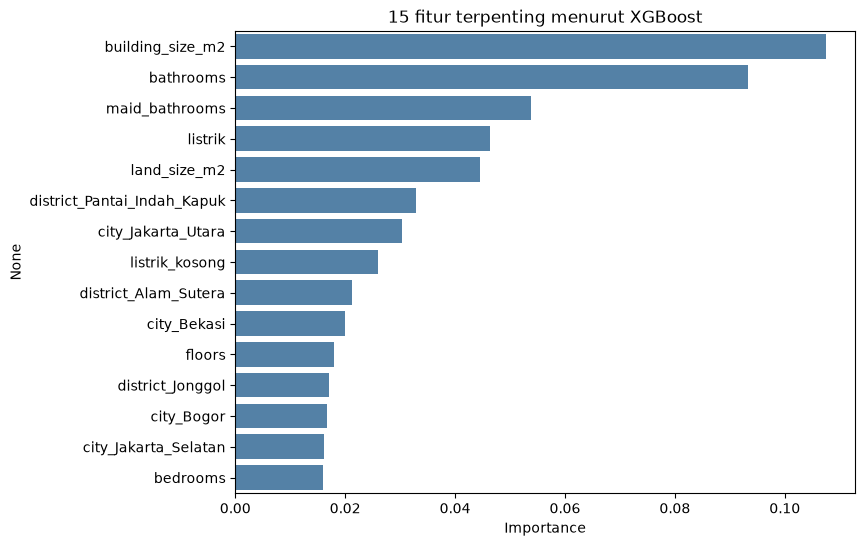

In [4]:
importance = (pd.Series(model.feature_importances_, index=X_test.columns)
                .sort_values(ascending=False)
                .head(15))

plt.figure(figsize=(8, 6))
sns.barplot(x=importance.values, y=importance.index, color="steelblue")
plt.xlabel("Importance")
plt.title("15 fitur terpenting menurut XGBoost")
plt.show()

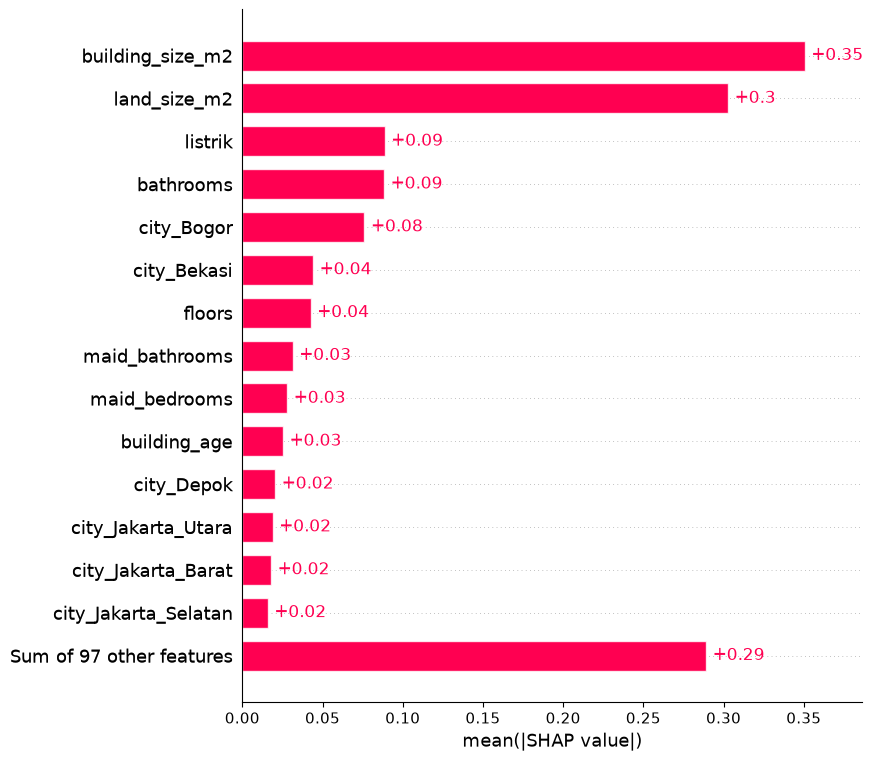

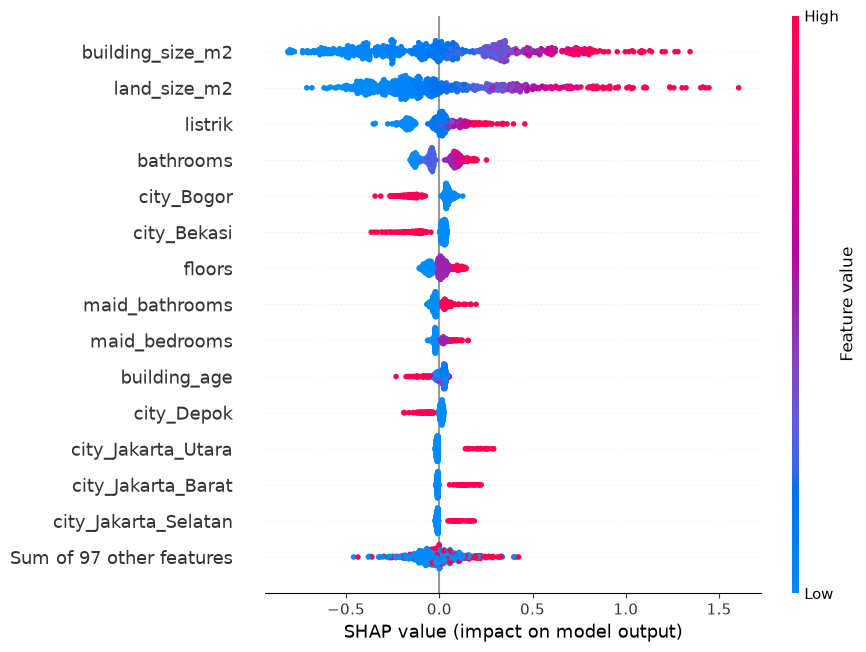

In [5]:
import shap

explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test)

shap.plots.bar(shap_values, max_display=15)
shap.plots.beeswarm(shap_values, max_display=15)

Menurut SHAP, harga paling ditentukan oleh luas bangunan dan luas tanah, jauh di atas fitur lain. Feature importance bawaan XGBoost menempatkan kamar mandi di atas, tapi SHAP lebih bisa dipercaya karena mengukur pengaruh nyata ke tebakan. Lokasi juga terlihat: rumah di Bogor ditaksir ±14% lebih murah dari rumah sejenis di tempat lain.

Harga asli : 2700.0 juta
Tebakan    : 3186.3 juta


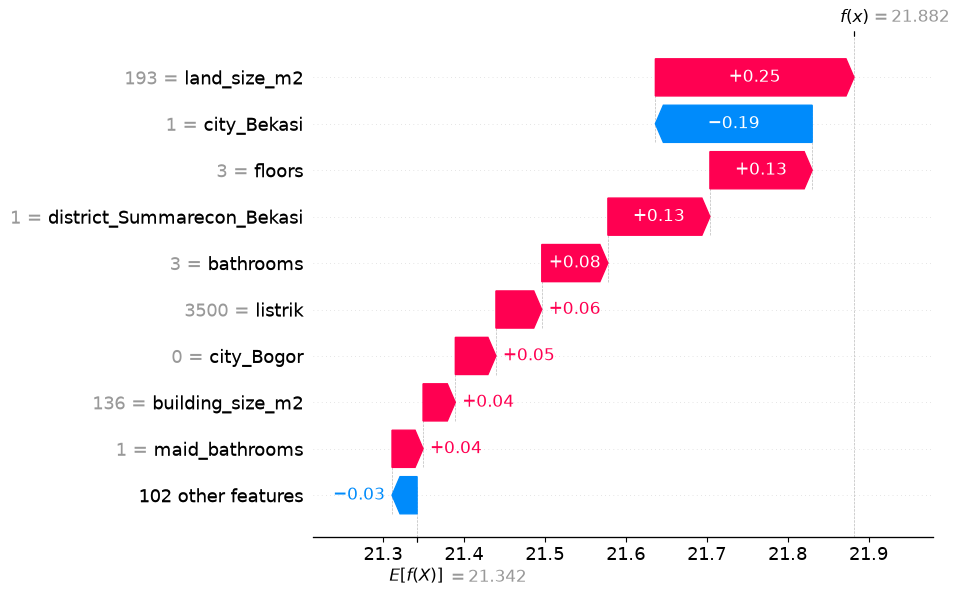

In [6]:
i = 0
print("Harga asli :", round(ev.loc[i, "asli_juta"], 1), "juta")
print("Tebakan    :", round(ev.loc[i, "tebakan_juta"], 1), "juta")

shap.plots.waterfall(shap_values[i], max_display=10)

In [7]:
ev["luas_tanah"] = X_test["land_size_m2"]
kolom_district = [c for c in X_test.columns if c.startswith("district_")]
ev["district"] = X_test[kolom_district].idxmax(axis=1).str.replace("district_", "")

parah = ev[ev["meleset_pct"] > 100].sort_values("meleset_pct", ascending=False)
print(len(parah), "rumah meleset lebih dari 100%")
parah

10 rumah meleset lebih dari 100%


,asli_juta,tebakan_juta,meleset_pct,arah,kota,luas_bangunan,kelas_harga,luas_tanah,district
523,"5,000.0","19,886.4",297.7,kemahalan,Tangerang,500.0,sangat mahal,"1,884.0",BSD_City
278,"3,500.0","13,737.9",292.5,kemahalan,Bogor,350.0,mahal,"4,445.0",lainnya
115,160.0,437.3,173.3,kemahalan,Bekasi,50.0,murah,60.0,lainnya
69,320.0,868.0,171.2,kemahalan,Bekasi,135.0,murah,108.0,Bekasi_Utara
214,"5,200.0","13,675.8",163.0,kemahalan,Bogor,"1,200.0",sangat mahal,983.0,Sentul
577,"32,000.0","83,874.5",162.1,kemahalan,Tangerang,"1,500.0",sangat mahal,"1,340.0",Karawaci
276,"7,500.0","17,431.2",132.4,kemahalan,Bogor,"1,000.0",sangat mahal,"4,704.0",lainnya
177,"1,900.0","4,232.7",122.8,kemahalan,Bogor,250.0,mahal,379.0,Sentul_City
260,"1,500.0","3,304.5",120.3,kemahalan,Bogor,150.0,sedang,"1,000.0",lainnya
607,"1,100.0","2,362.9",114.8,kemahalan,Tangerang,160.0,sedang,110.0,lainnya


## Keterbatasan
- Harga iklan 2022, bukan harga transaksi.
- Lokasi hanya level kecamatan; akses jalan dan lingkungan tidak ada di data.
- Model pohon tidak bisa menaksir di atas harga tertinggi yang pernah dilihat.
- Beberapa rumah meleset >100% dan penyebabnya belum diselidiki.